# Diffusion and adsorbtion

## Diffusion

In [1]:
import joblib

import pandas as pd

diff_loaded = joblib.load('../data/processed/diffusion_extrap_place_holder_model.pkl')
diff_loaded.predict(pd.DataFrame({'n': [2, 4, 6, 8, 10, 12], 'temperature': [300, 320, 301, 500, 100, 300]}))

array([1.26225909e-07, 5.07443613e-08, 3.28163345e-08, 6.32792274e-08,
       9.26861942e-11, 3.35152383e-08])

## Adsorbtion

In [3]:
from kinetic_model.constants.adsorption import *

X_test = pd.DataFrame({
        'pressure_bar': [1, 5, 10, 15, 20],
        'temperature': [300, 320, 301, 500, 100],
        'n':           [2, 4, 6, 8, 10],
        'adsorption_type_num': [0, 0, 0, 0, 1], # 0 - absolute, 1 - excess
    })
ads_model_loaded = joblib.load('../data/adsorption/adsorption_ensemble_model.pkl')

ads_model_loaded.predict(X_test)

array([  2.02952101,  25.19148163,   1.16094442,   0.37976969,
       -17.09994844])

# Examples of using Reaction class

{'A': [(('A', 'B'), -0.001)],
 'B': [(('A', 'B'), -0.001)],
 'C': [(('A', 'B'), 0.001)]}

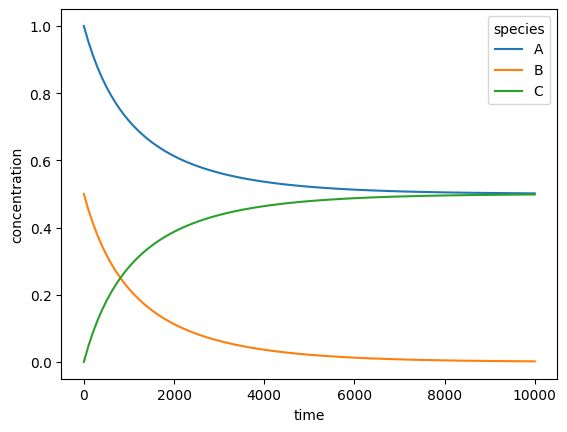

In [3]:
import numpy as np
import seaborn as sns
from kinetic_model.core.reactor import Reaction

# define a not reversible reaction: A + B -> C with k_forward=1e-3
reaction_list = [['A + B -> C', 1e-3]]
reactor = Reaction(reaction_list)
df = reactor.solve({'A': 1.0, 'B': .5, 'C': 0.0}, time_points=np.linspace(0, 10000, 100))
df['time'] = df.index
df = df.melt(id_vars='time', var_name='species', value_name='concentration')
sns.lineplot(data=df, x='time', y='concentration', hue='species')
reactor.reaction_dict

{'A': [(('A',), -0.1), (('B',), 0.05)], 'B': [(('A',), 0.1), (('B',), -0.05)]}

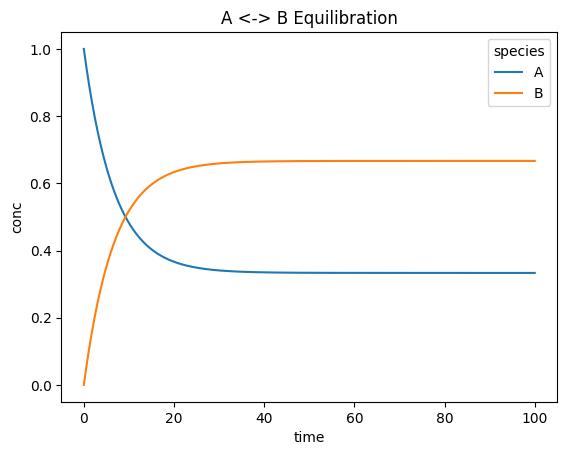

In [4]:
# define a reversible reaction: A <-> B with k_forward=0.1, k_backward=0.05
reaction_list = [['A <-> B', 0.1, 0.05]]
reactor = Reaction(reaction_list)

# simulate from t=0 to 100
time = np.linspace(0, 100, 500)
df_rev = reactor.solve({'A': 1.0, 'B': 0.0}, time)

# reshape and plot
df_rev['time'] = df_rev.index
dfm = df_rev.melt(id_vars='time', var_name='species', value_name='conc')
sns.lineplot(data=dfm, x='time', y='conc', hue='species').set_title("A <-> B Equilibration")
reactor.reaction_dict

Text(0.5, 1.0, 'A+B→C→D Chain Dynamics')

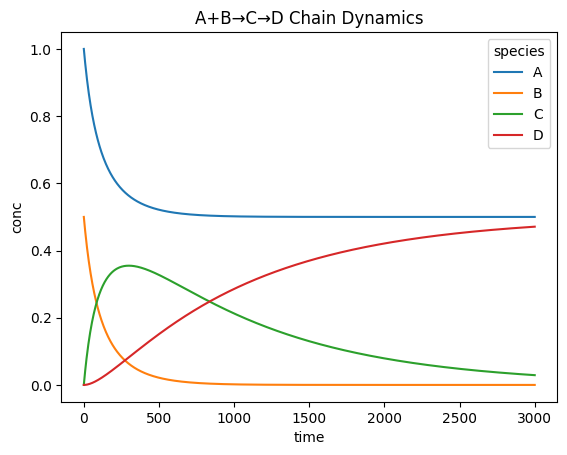

In [5]:
# two‐step network: A+B->C (k1), C->D (k2)
reaction_list = [
    ['A + B -> C', 1e-2],   # bimolecular
    ['C -> D',      1e-3]   # monomolecular
]
reactor = Reaction(reaction_list)

time = np.linspace(0, 3000, 1000)
initial = {'A':1.0, 'B':0.5, 'C':0.0, 'D':0.0}
df_net = reactor.solve(initial, time)

# plot all four species
df_net['time'] = df_net.index
dfm = df_net.melt(id_vars='time', var_name='species', value_name='conc')
sns.lineplot(data=dfm, x='time', y='conc', hue='species')\
   .set_title("A+B→C→D Chain Dynamics")


Text(0.5, 1.0, 'With [B] Buffered at 0.5')

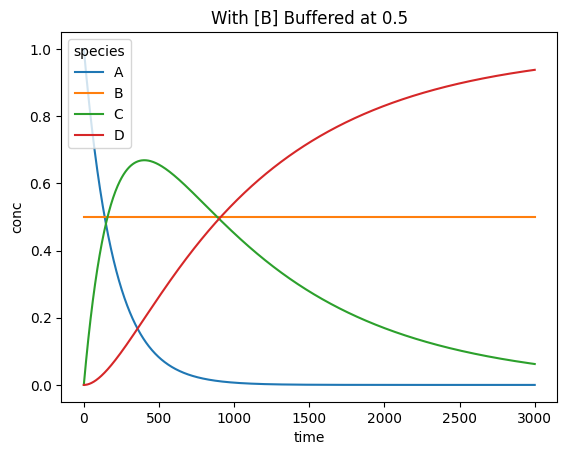

In [ ]:
# same chain, but fix [B] = 0.5 throughout
reactor = Reaction(reaction_list, fixed_concentrations=['B'])
df_buf = reactor.solve({'A':1.0, 'B':0.5, 'C':0.0, 'D':0.0}, time)

# plot
df_buf['time'] = df_buf.index
dfm = df_buf.melt(id_vars='time', var_name='species', value_name='conc')
sns.lineplot(data=dfm, x='time', y='conc', hue='species')\
   .set_title("With [B] Buffered at 0.5")


In [6]:
reactor.reaction_dict 

{'A': [(('A', 'B'), -0.01)],
 'B': [(('A', 'B'), -0.01)],
 'C': [(('A', 'B'), 0.01), (('C',), -0.001)],
 'D': [(('C',), 0.001)]}

Text(0.5, 1.0, 'With [B] Buffered at 0.5')

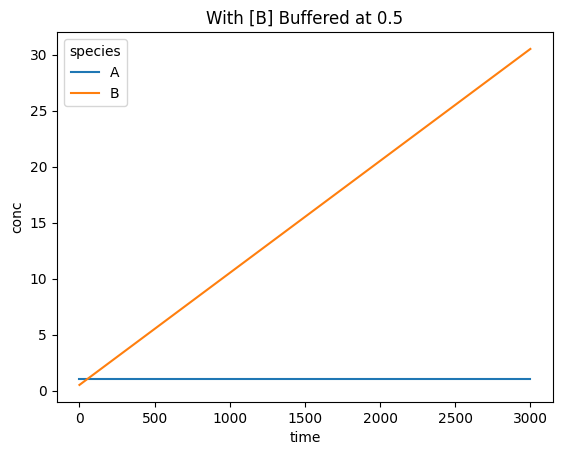

In [19]:
# simple example with fixed concentration of one species
reaction_list = [
    ['A -> B', 1e-2, 1e-2]   # monomolecular
]
reactor = Reaction(reaction_list, fixed_concentrations=['A'])
df_buf = reactor.solve({'A':1.0, 'B':0.5}, time)

# plot
df_buf['time'] = df_buf.index
dfm = df_buf.melt(id_vars='time', var_name='species', value_name='conc')
sns.lineplot(data=dfm, x='time', y='conc', hue='species')\
   .set_title("With [B] Buffered at 0.5")

# Diffusion examples

Text(0.5, 1.0, 'Diffusion of X from A to B')

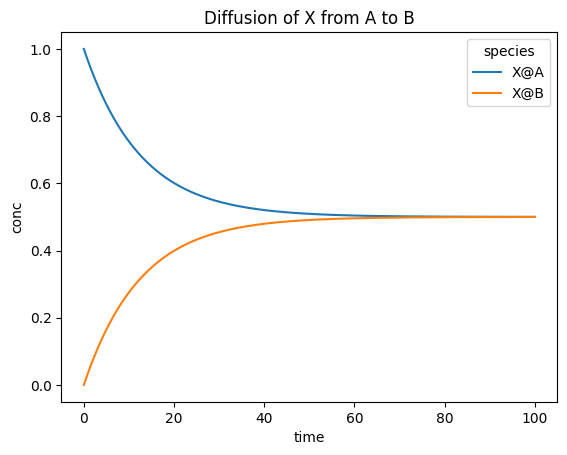

In [20]:
# In[1] — imports and setup
import numpy as np
import seaborn as sns
import pandas as pd
from kinetic_model.core.diffusion import Reaction_Diffusion

# define diffusion: X@A <D> X@B with rate k
# notation “X@A” means species X in compartment A
reaction_list = [['X@A <D> X@B', 0.02, 0.02]]
capacities = {'X@A': 1.0, 'X@B': 1.0}

reactor = Reaction_Diffusion(reactions=reaction_list,
                              capacity=capacities)

# time grid
time = np.linspace(0, 100, 500)

# start with all X in compartment A, none in B
initial = {'X@A': 1.0, 'X@B': 0.0}

# solve ODEs
df_diff = reactor.solve(initial_concs_dict=initial,
                        time_points=time)

# reshape for plotting
df_diff['time'] = df_diff.index
dfm = df_diff.melt(id_vars='time', var_name='species', value_name='conc')

# plot
sns.lineplot(data=dfm, x='time', y='conc', hue='species')\
   .set_title("Diffusion of X from A to B")


Text(0.5, 1.0, 'Diffusion with B twice the capacity of A')

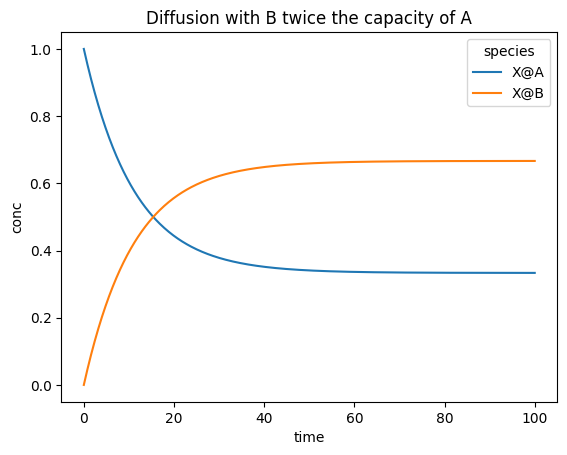

In [21]:
# In[2] — unequal capacities
capacities = {'X@A': 1.0, 'X@B': 2.0}
reactor = Reaction_Diffusion(reactions=reaction_list,
                             capacity=capacities)

# solve with same initial conditions and time grid
df_unequal = reactor.solve(initial, time)

# plot
df_unequal['time'] = df_unequal.index
dfm2 = df_unequal.melt(id_vars='time', var_name='species', value_name='conc')
sns.lineplot(data=dfm2, x='time', y='conc', hue='species')\
   .set_title("Diffusion with B twice the capacity of A")


Text(0.5, 1.0, 'A→C in A plus C diffusing to B')

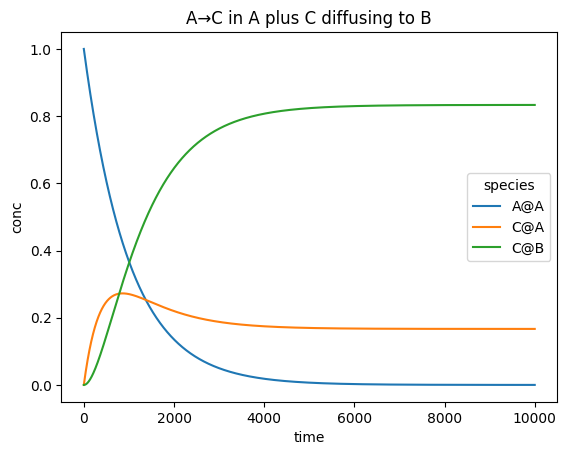

In [25]:
# In[3] — reaction plus diffusion
reaction_list = [
    ['A@A -> C@A',    1e-3],       # A→C in compartment A
    ['C@A <D> C@B',   5e-4, 2e-4]  # bidirectional diffusion of C
]
capacities = {'A@A':1.0, 'C@A':1.0, 'C@B':2.0}

reactor = Reaction_Diffusion(reactions=reaction_list,
                             capacity=capacities)

initial = {'A@A':1.0, 'C@A':0.0, 'C@B':0.0}

# time grid
time = np.linspace(0, 10000, 5000)

df_rxndiff = reactor.solve(initial, time)

# plot all three species
df_rxndiff['time'] = df_rxndiff.index
dfm3 = df_rxndiff.melt(id_vars='time', var_name='species', value_name='conc')
sns.lineplot(data=dfm3, x='time', y='conc', hue='species')\
   .set_title("A→C in A plus C diffusing to B")


Text(0.5, 1.0, 'With C@B Buffered at 0 (always zero since no inflow)')

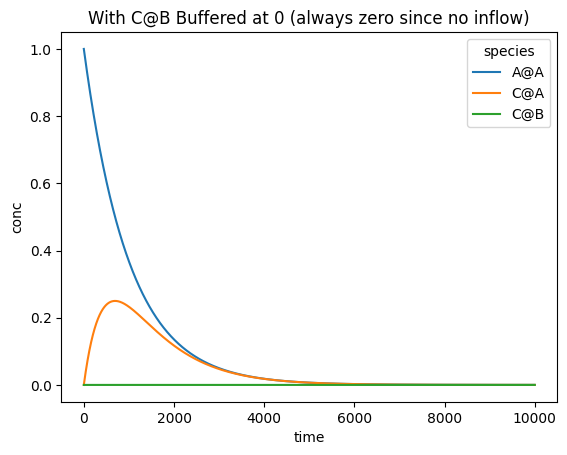

In [26]:
# In[4] — buffering C@B
reactor = Reaction_Diffusion(reactions=reaction_list,
                             capacity=capacities,
                             fixed_concentrations=['C@B'])

time = np.linspace(0, 10000, 5000)
df_buf = reactor.solve(initial, time)

df_buf['time'] = df_buf.index
dfm4 = df_buf.melt(id_vars='time', var_name='species', value_name='conc')
sns.lineplot(data=dfm4, x='time', y='conc', hue='species')\
   .set_title("With C@B Buffered at 0 (always zero since no inflow)")

# Create reaction list

In [12]:
import numpy as np
import pandas as pd
import seaborn as sns

from kinetic_model.simulation.reaction_list_creator import make_reaction_list_basic, prepare_constants_basic


N = 10

# our assumption is that the barrier ...

barrier_params = {
    'C2_ins':  84.382, 'C2_den': 100.151,
    'C2_ads': -73.930, 'C2_des':  73.930,
    'C4_ads': -78.151, 'C4_des':  78.151,
}
diffusion = {2:2.28, 4:0.70, 6:0.21, 8:0.07}

consts = prepare_constants_basic(barrier_params, n_max=6,
                            diffusion_rates=diffusion, T=300)

print("Constants:\n", consts)

basic = make_reaction_list_basic(10, consts, include_diffusion=False)
diff  = make_reaction_list_basic(10, consts, include_diffusion=True)

import pandas as pd
print("\nBasic reactions:\n", pd.DataFrame(basic, columns=['rxn','k_f','k_r']))
print("\nWith diffusion:\n", pd.DataFrame(diff, columns=['rxn','k_f','k_r']))

Constants:
 {'k_ins': np.float64(0.012676721798427304), 'k_deins': np.float64(2.2765699614678713e-05), 'k_ads_2': np.float64(10000000.0), 'k_des_2': np.float64(0.8373895659079054), 'k_ads_4': np.float64(10000000.0), 'k_des_4': np.float64(0.15415571017530688), 'k_diff_2': np.float64(2.28), 'k_diff_4': np.float64(0.7), 'k_diff_6': np.float64(0.21)}

Basic reactions:
                      rxn           k_f       k_r
0     Cat + C2 <-> CatC2  1.000000e+07  0.837390
1   CatC2 + C2 <-> CatC4  1.267672e-02  0.000023
2     Cat + C4 <-> CatC4  1.000000e+07  0.154156
3   CatC4 + C2 <-> CatC6  1.267672e-02  0.000023
4     Cat + C6 <-> CatC6  1.000000e+07  0.154156
5   CatC6 + C2 <-> CatC8  1.267672e-02  0.000023
6     Cat + C8 <-> CatC8  1.000000e+07  0.154156
7  CatC8 + C2 <-> CatC10  1.267672e-02  0.000023
8   Cat + C10 <-> CatC10  1.000000e+07  0.154156

With diffusion:
                       rxn           k_f       k_r
0      Cat + C2 <-> CatC2  1.000000e+07  0.837390
1    CatC2 + C2 <-> CatC

# Ckeck how it works together

In [13]:
import joblib
from kinetic_model.constants.diffusion import DiffusionLinear
from kinetic_model.constants.adsorption import AdsorptionKNN
from kinetic_model.simulation.reaction_list_creator import make_reaction_list_basic, prepare_constants_basic
from kinetic_model.constants.energy_profile import EnergyPlaceholder
import pandas as pd
import numpy as np

diff_loaded = joblib.load('../data/processed/diffusion_model.pkl')
ads_model_loaded = joblib.load('../data/processed/knn_adsorption_model.pkl')
energy_model = EnergyPlaceholder(pressure=np.nan, temperature=np.nan)
barrier_params = energy_model.get_params_basic()

N = 10
T = 300
pressure = 1.0 # bar
L = 20 # nm particle size

X = pd.DataFrame({
        'pressure_bar': [pressure] * N,
        'temperature': [T] * N,
        'n':           [i for i in range(2, N + 1, 2)] + \
                        [i for i in range(2, N + 1, 2)],
        'adsorption_type_num': [0] * (N//2) + [1] * (N//2), # 0 - absolute, 1 - excess
    })

diffusion = diff_loaded.predict(X)  / (L * 1e-9)
diffusion_constants = {(i + 1) * 2: diffusion[i] for i in range(N//2)}
adsorbtion = ads_model_loaded.predict(X)
capacity = {f'C{(i + 1) * 2}': adsorbtion[i] for i in range(N//2)}
capacity.update(
    {f'C{(i + 1) * 2}_out': adsorbtion[i] - adsorbtion[i + N//2] for i in range(N//2)} 
)

consts = prepare_constants_basic(barrier_params, delta_ads=1, delta_ins=2, n_max=N,
                            diffusion_rates=diffusion_constants, T=T)

reaction_list  = make_reaction_list_basic(N, consts, include_diffusion=True)
print("\nWith diffusion:\n", pd.DataFrame(reaction_list, columns=['rxn','k_f','k_r']))


With diffusion:
                       rxn           k_f       k_r
0      Cat + C2 <-> CatC2  1.000000e+07  0.560797
1    CatC2 + C2 <-> CatC4  5.685432e-03  0.000010
2           C2 <D> C2_out  6.311295e+00  6.311295
3      Cat + C4 <-> CatC4  1.000000e+07  0.103238
4    CatC4 + C2 <-> CatC6  5.685432e-03  0.000010
5           C4 <D> C4_out  2.112427e+00  2.112427
6      Cat + C6 <-> CatC6  1.000000e+07  0.103238
7    CatC6 + C2 <-> CatC8  5.685432e-03  0.000010
8           C6 <D> C6_out  1.629439e+00  1.629439
9      Cat + C8 <-> CatC8  1.000000e+07  0.103238
10  CatC8 + C2 <-> CatC10  5.685432e-03  0.000010
11          C8 <D> C8_out  1.198108e+00  1.198108
12   Cat + C10 <-> CatC10  1.000000e+07  0.103238
13        C10 <D> C10_out  1.146141e+00  1.146141


<Axes: xlabel='n', ylabel='probability'>

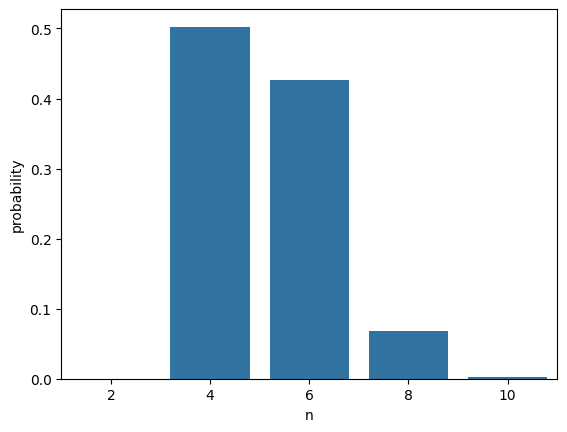

In [14]:
# In[1] — imports and setup
import numpy as np
import seaborn as sns
from kinetic_model.core.diffusion import Reaction_Diffusion
import re

reactor = Reaction_Diffusion(reactions=reaction_list,
                              capacity=capacity)

# time grid
time = np.linspace(0, 3600*2, 10000)

# start with all X in compartment A, none in B
initial = {'Cat': 1e-2, 'C2': 1.0}

# solve ODEs
df_diff = reactor.solve(initial_concs_dict=initial,
                        time_points=time)

def calc_distribution(result):
    pat = re.compile(r'\bC(\d+)')
    columns = list(filter(lambda x: pat.match(x), result.columns.values))
    df = result[columns].iloc[-1:]
    df = df.mean()
    df = df.reset_index(name='concentration')
    df['n'] = df['index'].str.extract(r'(\d+)')[0].astype(int)
    df = df.groupby('n').sum(numeric_only=True)
    df['probability'] = df['concentration'] / df.loc[4:, 'concentration'].sum()
    df.loc[2, 'probability'] = np.nan
    return df.reset_index()

distribution = calc_distribution(df_diff)
sns.barplot(data=distribution, x='n', y='probability')

# Plot energy profile old version

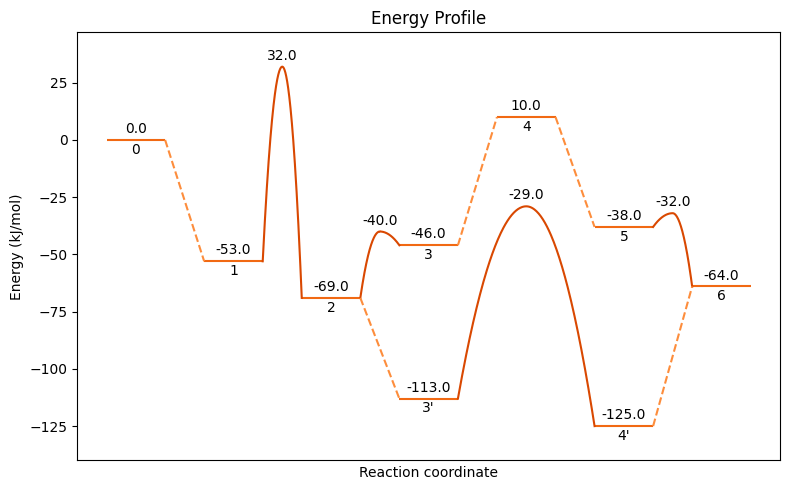

In [29]:
from kinetic_model.simulation.plot import plot_energy_profile
from kinetic_model.simulation.synthetic_data import get_reaction_profile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pallate = ['#fd8d3c','#f16913','#d94801']

df, connections = get_reaction_profile('Ni_dimer_2_paths')

fig, ax = plt.subplots(figsize=(8,5))
plot_energy_profile(
    df, ax,
    m=0.6,
    annotate_states=True,
    delta_text_energy=3,
    delta_text_state=-6,
    connections=connections,
    pallate=pallate
)
plt.tight_layout()
plt.show()

# Energy profile DFT

In [1]:
from kinetic_model.energy_profile.energy_processing import calculate_relative_energies, calculate_energies_with_references
from kinetic_model.energy_profile.energy_profile import EnergyProfile
import os
import pandas as pd

In [2]:
temperatures = [300.00 * 1]     # Can be varied
pressures = [101325. * 1]       # Can be carried
model = 'formate_PBED3BJ'   # Only model in the current demo version
pathway = 'agostic' # Only pathway in the current demo version
ref_struc = '1'             # Choose either 1 or 5
energy_type = 'Gibbs free energy'   # Choose one of ['Electronic energy', 'Enthalpy', 'Gibbs free energy']
energy_unit = 'kJ/mol'      # Choose one of ['eV', 'kJ/mol', 'kcal/mol']

custom_order = ["1", "2", "3", "4", "5", "5a", "6", "7", "8", "1p", "2-3", "3-4", "6-1p", "7-8"]  # Use for sorting the intermediates in a table (or pd.DataFrame)

rel_results = calculate_relative_energies(
    structures_dir=os.path.abspath('../data/structures'),
    molecules_dir=os.path.abspath('../data/gas-phase-molecules'),
    temperatures=temperatures,
    model=model,
    ref_struc=ref_struc,
    pathway=pathway,
    pressures=pressures
)

In [3]:
import yaml
from collections import OrderedDict

columns_to_display = ['model', 'method', 'pathway', 'system', 'system_name', 'order', 'pressure', 'temperature', 'rel_E_eV', 'rel_H_eV', 'rel_G_eV']

# Filter only rows where 'order' is in the custom_order list
rel_results_filtered = rel_results[rel_results['order'].isin(custom_order)].copy()

# Assign the categorical order
rel_results_filtered['order'] = pd.Categorical(
    rel_results_filtered['order'], categories=custom_order, ordered=True
)

# Sort and select columns
rel_results_sorted = rel_results_filtered.sort_values(by='order')
formatted_df = rel_results_sorted[columns_to_display]

add_energies = True # Add the energy of the plotted intermediates and TS
add_names = True    # Add the name of the plotted intermediates
energy_type='Gibbs free energy'
energy_unit = 'kJ/mol'

# This gives general settings for the plot
with open(os.path.abspath('../data/settings.yaml'), "r") as f:
            settings = yaml.safe_load(f)

# This gives more information on the sequences of intermediates to be plotted, the respective labels and colors
with open(os.path.abspath('../data/energy_profiles_settings.yaml'), "r") as f:
            plot_settings = yaml.safe_load(f)

EP = EnergyProfile(
    formatted_df, 
    energy_type=energy_type, 
    energy_unit=energy_unit)

systems_ls = []
labels = []
for line in plot_settings['sequences']:
    systems = line.split(sep='-->')
    systems_ls.append(systems)
try:
    colors = plot_settings['colors']
except:
    colors = settings['color_palette'][1:]

position_map = OrderedDict()
for systems in systems_ls:
    for i, system in enumerate(systems):
        position = 2 * i
        if system not in position_map:
            position_map[system] = position

EP.plot()
energy_values = []
for systems in systems_ls:
    tmp_values = EP.get_energy_range(systems)
    energy_values.extend(tmp_values)

ymin = min(energy_values)
ymax = max(energy_values)
yrange = ymax - ymin
padding = 0.10 * yrange

for i, systems in enumerate(systems_ls):
    for system in systems:
        position = position_map[system]

        if system == systems[0]:
            EP.add_level(system=system, 
                         position=position, 
                         label=plot_settings['labels'][i], 
                         color=colors[i])
        else:
            EP.add_level(system=system, 
                         position=position, 
                         color=colors[i])

        # EP.add_intermediate_energy_label(system=system, 
        #                                  position=position, 
        #                                  fontsize=18)

    for system1, system2 in zip(systems[:-1], systems[1:]):
        EP.add_connection(system1=system1, 
                          system2=system2, 
                          color=colors[i])
        EP.add_ts_energy_label(system1=system1, 
                               system2=system2,
                               fontsize=18)
        
if add_energies:
    for i, systems in enumerate(systems_ls):
        for j, system in enumerate(systems):
            position = position_map[system]
            EP.add_intermediate_energy_label(system=system, 
                                               position=position, 
                                               fontsize=18)
        for system1, system2 in zip(systems[:-1], systems[1:]):
            EP.add_ts_energy_label(system1=system1, 
                                   system2=system2,
                                   fontsize=18)
if add_names:
    for i, systems in enumerate(systems_ls):
        for j, system in enumerate(systems):
            position = position_map[system]
            EP.add_structure_name(system=system,
                                  position=position, 
                                  fontsize=18)
     
EP.show(ymin=ymin,
        ymax=ymax,
        padding=padding,
        legend=True)

# Simulation

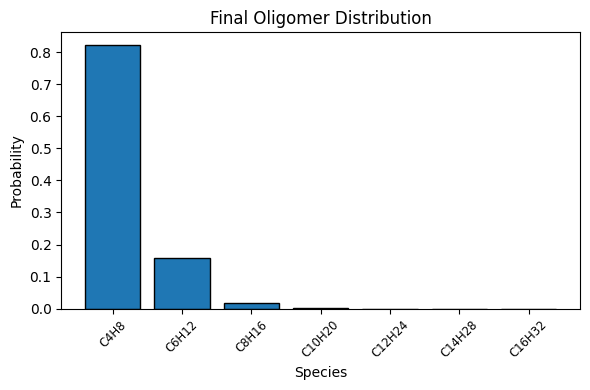

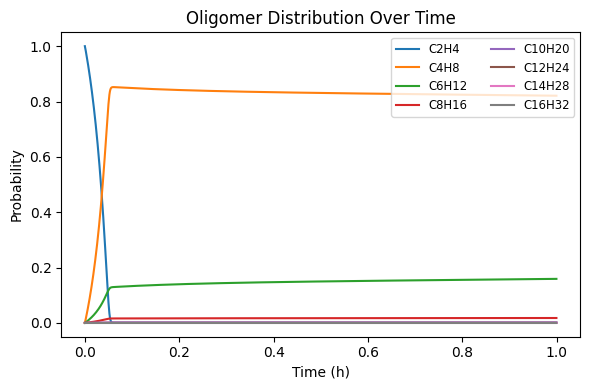

In [27]:
from kinetic_model.constants.energy_profile import EnergyBarriers
from kinetic_model.simulation.run_reactor import ReactorSimulationChemisorption
import joblib
import pandas as pd
import seaborn as sns

N = 16
temperature = 330.00  # Kelvin
pressure = 1  # bar

energy_barriers = EnergyBarriers(
    structures_dir='../data/structures',
    molecules_dir='../data/gas-phase-molecules',
    model='formate_PBED3BJ',
    pathway='agostic',
    ref_struc='1',
    temperature=temperature,
    pressure=pressure,
    custom_order=["1", "2", "3", "4", "5", "5a", "6", "7", "8", "1p", "2-3", "3-4", "6-1p", "7-8"],
    energy_type='Gibbs free energy',
    energy_unit='kJ/mol'
)

energy_barriers_dict = energy_barriers.get_energy_barriers()

reactor = ReactorSimulationChemisorption(
                N=N,
                T=temperature,
                pressure=pressure,
                L=20,
                delta_ins=0.0,
                delta_ads=0.0,
                delta_recomb=0.0,
                time_hours=1.0,
                n_steps=int(1e6),
                diff_model_path='../data/processed/diffusion_extrap_place_holder_model.pkl',
                ads_model_path='../data/processed/knn_adsorption_slope_model.pkl',
                energy_model=energy_barriers,
                initial_concs={'Cat': 1e-2, 'C2': 1}
)


distr, ts = reactor.run()
import matplotlib.pyplot as plt
labels = [f'C{n}H{2*n}' for n in distr['n']]
plt.figure(figsize=(6,4))
plt.bar(labels, distr['probability'], edgecolor='k')
plt.xlabel('Species')
plt.ylabel('Probability')
plt.title('Final Oligomer Distribution')
plt.xticks(rotation=45, fontsize='small')
plt.tight_layout()

# %% 
# 3) Line plot of distribution over time
plt.figure(figsize=(6,4))
for n in ts.columns:
    lbl = f'C{n}H{2*n}'
    plt.plot(ts[::1000].index/3600, ts.loc[::1000, n], label=lbl)
plt.xlabel('Time (h)')
plt.ylabel('Probability')
plt.title('Oligomer Distribution Over Time')
plt.legend(fontsize='small', ncol=2, loc='upper right')
plt.tight_layout()